Train skup: 2016-06-12 → 2025-03-09 (457 nedelja)
Test skup:  2025-03-16 → 2025-06-01 (poslednjih 12 nedelja)

─── VALIDACIJA (Poslednjih 12 nedelja) ─────────────────
      Date    Return  Realizovana_Vol  GARCH_Vol
2025-03-16 -0.597481             1.02   1.558075
2025-03-23  0.120215             0.86   1.449923
2025-03-30  1.182230             0.72   1.345513
2025-04-06  3.706070             2.24   1.308302
2025-04-13  0.281665             2.46   1.719998
2025-04-20 -0.245765             1.40   1.589155
2025-04-27 -0.607127             1.97   1.474253
2025-05-04 -0.424929             0.89   1.383830
2025-05-11 -0.746799             1.14   1.295866
2025-05-18  1.800430             1.87   1.232487
2025-05-25 -0.149582             1.07   1.291607
2025-06-01  0.414170             1.08   1.208604


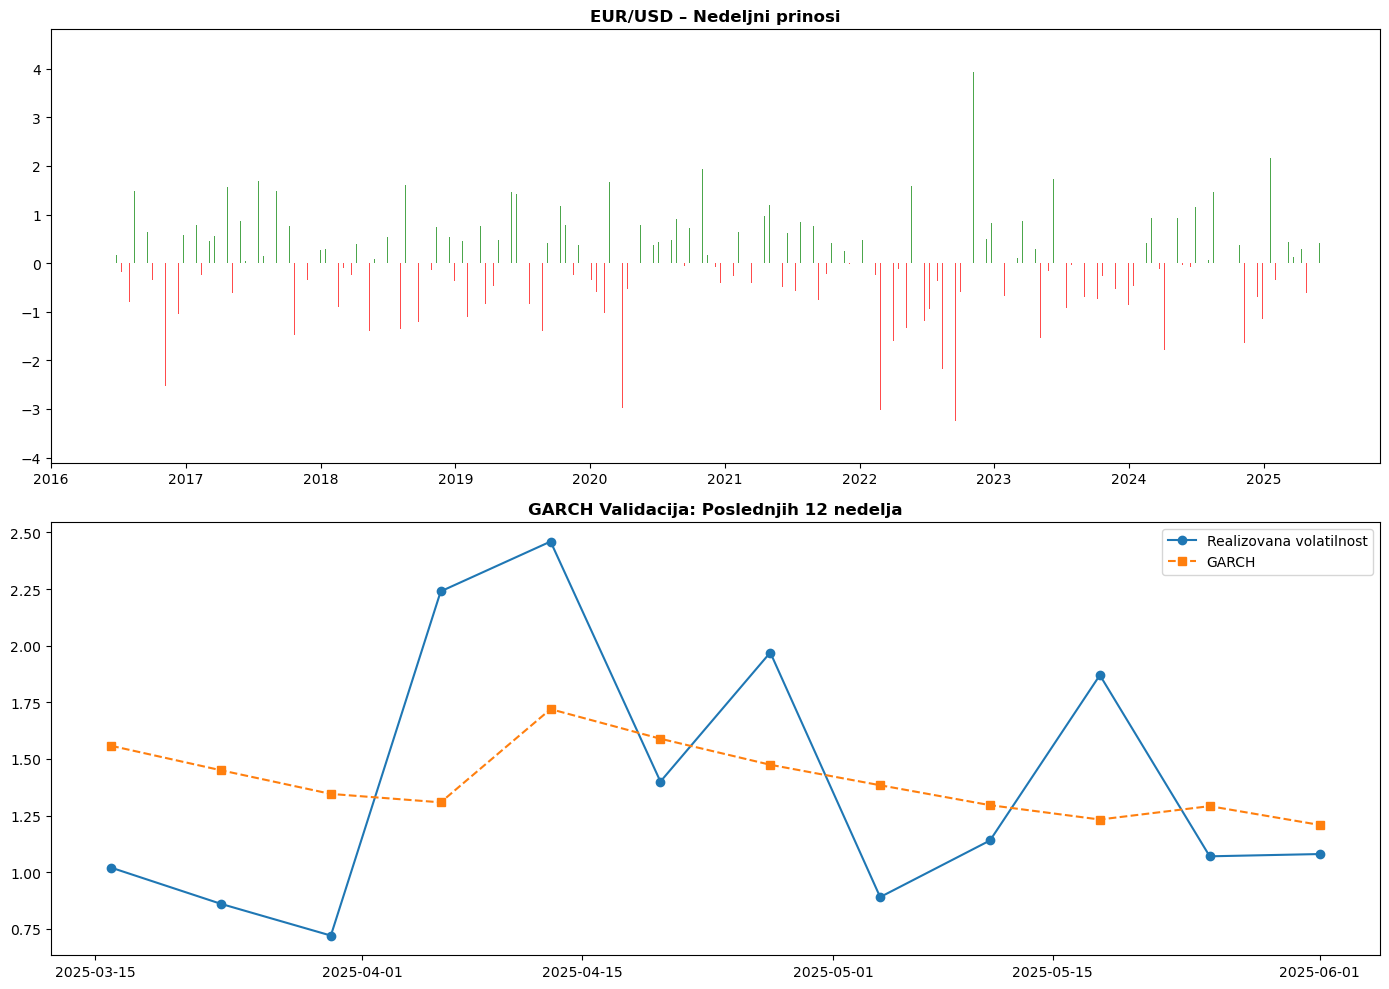

                     Constant Mean - GARCH Model Results                      
Dep. Variable:                 Return   R-squared:                       0.000
Mean Model:             Constant Mean   Adj. R-squared:                  0.000
Vol Model:                      GARCH   Log-Likelihood:               -636.825
Distribution:                  Normal   AIC:                           1281.65
Method:            Maximum Likelihood   BIC:                           1298.15
                                        No. Observations:                  457
Date:                Sat, May 30 2026   Df Residuals:                      456
Time:                        18:18:23   Df Model:                            1
                                  Mean Model                                 
                 coef    std err          t      P>|t|       95.0% Conf. Int.
-----------------------------------------------------------------------------
mu            -0.0116  4.356e-02     -0.266      0.790 

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from arch import arch_model

# ── UČITAVANJE PODATAKA ─────────────────────────────────────
df = pd.read_csv('/Users/tamaradrca/Podaci za diplomski/EUR_USD Historical Data .csv')
df['Date'] = pd.to_datetime(df['Date'])
df = df.sort_values('Date').reset_index(drop=True)

# Čišćenje cene
df['Price'] = df['Price'].astype(str).str.replace(',', '').astype(float)
df = df[['Date', 'Price']].dropna().drop_duplicates(subset=['Date'])

# Nedeljni prinos u %
df['Return'] = 100 * df['Price'].pct_change()
df = df.dropna().reset_index(drop=True)

# ── 1. PODELA PODATAKA (IZMENJENO: POSLEDNJIH 12 NEDELJA) ────
# Prvo definišemo test set kao poslednjih 12 dostupnih nedelja
test = df.tail(12).copy()

# Train set su svi podaci pre prve nedelje u test setu
test_start_date = test['Date'].min()
train = df[df['Date'] < test_start_date].copy()

print(f"Train skup: {train['Date'].min().date()} → {train['Date'].max().date()} ({len(train)} nedelja)")
print(f"Test skup:  {test['Date'].min().date()} → {test['Date'].max().date()} (poslednjih {len(test)} nedelja)")

# ── 2. FIT GARCH(1,1) NA TRENING SETU ──────────────────────
model     = arch_model(train['Return'], vol='Garch', p=1, q=1, dist='normal')
model_fit = model.fit(disp='off')

# ── 3. ROLLING FORECAST ZA TEST SET ────────────────────────
pred_vols = []
for i in range(len(test)):
    # Uzimamo sve podatke do trenutne nedelje u testu
    cutoff = test['Date'].iloc[i - 1] if i > 0 else train['Date'].max()
    train_expanded = df[df['Date'] <= cutoff].copy()

    m  = arch_model(train_expanded['Return'], vol='Garch', p=1, q=1, dist='normal')
    mf = m.fit(disp='off')
    fc = mf.forecast(horizon=1)
    vol = np.sqrt(fc.variance.values[-1, 0])
    pred_vols.append(vol)

test['GARCH_Vol'] = pred_vols
stvarne_eur = [1.02, 0.86, 0.72, 2.24, 2.46, 1.40, 1.97, 0.89, 1.14, 1.87, 1.07, 1.08]
test['Realizovana_Vol'] = stvarne_eur

print("\n─── VALIDACIJA (Poslednjih 12 nedelja) ─────────────────")
print(test[['Date', 'Return', 'Realizovana_Vol', 'GARCH_Vol']].to_string(index=False))



# ── 5. VIZUALIZACIJA ────────────────────────────────────────
fig, axes = plt.subplots(2, 1, figsize=(14, 10))

# Graf 1: Prinosi
axes[0].bar(df['Date'], df['Return'], 
            color=['green' if r > 0 else 'red' for r in df['Return']], alpha=0.7)
axes[0].set_title('EUR/USD – Nedeljni prinosi', fontweight='bold')

# Graf 2: Validacija poslednjih 12 nedelja + 4 nove
future_dates = pd.date_range(start=df['Date'].max() + pd.Timedelta(weeks=1), periods=4, freq='W-MON')

axes[1].plot(test['Date'], test['Realizovana_Vol'], marker='o', label='Realizovana volatilnost')
axes[1].plot(test['Date'], test['GARCH_Vol'], marker='s', linestyle='--', label='GARCH')

axes[1].set_title('GARCH Validacija: Poslednjih 12 nedelja', fontweight='bold')
axes[1].legend()

plt.tight_layout()
plt.show()
print(model_fit.summary()) 
# Snimanje datuma za onaj drugi kod
test[['Date']].to_csv('garch_dates.csv', index=False)
print("\nDatumi (poslednjih 12 nedelja) su sačuvani u garch_dates.csv")